**Zadanie 1**


Narysuj koło o środku w punkcie (0,0) i promieniu 2. Powinno być ono wypełnione półprzezroczystą barwą zieloną, mieć wyraźnie zaznaczony brzeg i nie wyglądać jak elipsa.

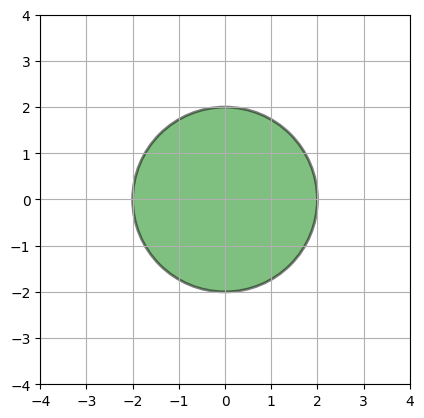

In [2]:
import matplotlib.pyplot as plt

# wykres
fig, ax = plt.subplots()

kolo = plt.Circle((0, 0), 2, facecolor='green', edgecolor='black', linewidth=2, alpha=0.5)
ax.add_patch(kolo)

# Ustawiamy granice osi X i Y, żeby całe koło było dobrze widoczne
ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)

# Ustawiamy równe proporcje osi aby bylo okragle
ax.set_aspect('equal')

# Włączamy siatkę i pokazujemy wynik
plt.grid(True)
plt.show()

**Zadanie 2**

Korzystając z pakietu seaborn i danych tips, narysuj wykresy:

a) Dwa wykresy (kołowy i słupkowy), które będą podsumowywać zmienną smoker.

b) Utwórz wykres skrzynkowy dla procentowego udziału napiwku w całkowitej wartości rachunku w rozbiciu na podgrupy generowane przez kombinacje sex i day.

c) Utwórz wykres skrzynkowy dla procentowego udziału napiwku w całkowitej wartości rachunku na podstawie ramki danych tips.

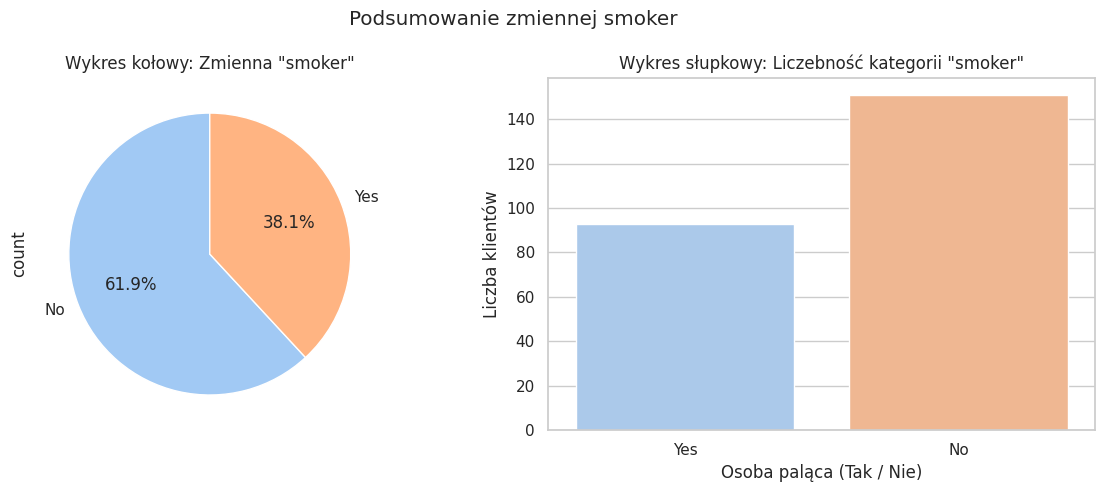

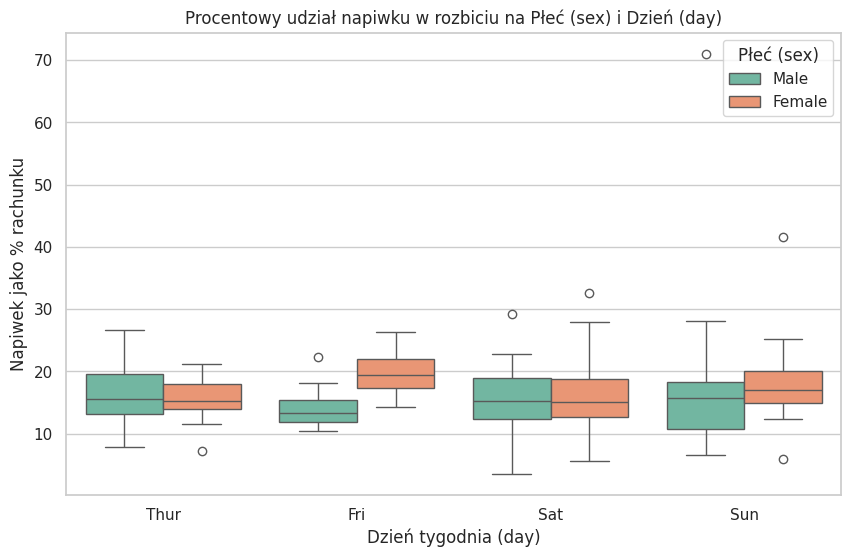

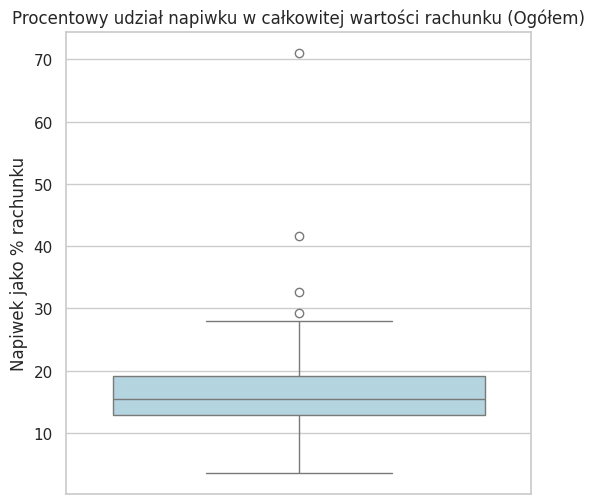

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Ustawienie stylu wykresow
sns.set_theme(style="whitegrid")

# Wczytanie wbudowanego zbioru danych 'tips'
tips = sns.load_dataset('tips')

# Obliczenie procentowego udziału napiwku w całkowitej wartości rachunku
tips['tip_pct'] = (tips['tip'] / tips['total_bill']) * 100

# a) Wykresy podsumowujące zmienną 'smoker'
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Wykres kołowy
smoker_counts = tips['smoker'].value_counts()
smoker_counts.plot.pie(
    autopct='%1.1f%%',
    ax=axes[0],
    colors=sns.color_palette("pastel"),
    startangle=90
)
axes[0].set_title('Wykres kołowy: Zmienna "smoker"')

# 2. Wykres słupkowy
sns.countplot(
    data=tips,
    x='smoker',
    ax=axes[1],
    palette="pastel",
    hue='smoker',
    legend=False
)
axes[1].set_title('Wykres słupkowy: Liczebność kategorii "smoker"')
axes[1].set_xlabel('Osoba paląca (Tak / Nie)')
axes[1].set_ylabel('Liczba klientów')

plt.suptitle('Podsumowanie zmiennej smoker')
plt.tight_layout()
plt.show()

# b) Wykres skrzynkowy: udział napiwku z podziałem na sex i day
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=tips,
    x='day',
    y='tip_pct',
    hue='sex',
    palette='Set2'
)
plt.title('Procentowy udział napiwku w rozbiciu na Płeć (sex) i Dzień (day)')
plt.xlabel('Dzień tygodnia (day)')
plt.ylabel('Napiwek jako % rachunku')
plt.legend(title='Płeć (sex)')
plt.show()

# c) Wykres skrzynkowy: procentowy udział napiwku na podstawie całej ramki danych
plt.figure(figsize=(6, 6))
sns.boxplot(
    data=tips,
    y='tip_pct',
    color='lightblue'
)
plt.title('Procentowy udział napiwku w całkowitej wartości rachunku (Ogółem)')
plt.ylabel('Napiwek jako % rachunku')
plt.show()

**Zadanie 3**


Korzystając z pliku ssl.csv, wykonaj następujące zadania:

a) Odczytaj dane z kolumny cipher i zidentyfikuj najczęściej używane algorytmy szyfrujące. Dane przedstaw na wykresie i odpowiedz, czy najpopularniejszy algorytm jest bezpiecznym rozwiązaniem.

b) Bazując na danych z pliku i kolumnie source_ip, wyszukaj stacje robocze lub serwery generujące największy ruch SSL. Przedstaw na wykresie 6 najaktywniejszych urządzeń.

c) Kolumna certificate_validation_status zawiera dane o certyfikatach. Przedstaw na wykresie kołowym informacje zawarte w tej kolumnie. Sprawdź, jaki rodzaj certyfikatu występuje najczęściej. W kolumnie może wystąpić znak "-", co oznacza brak danych o certyfikacie; takie informacje również zamieść na wykresie.

d) Kolumna timestamp_unix zawiera znacznik czasowy. Przekonwertuj ją na czas i policz, ile połączeń występuje w każdej godzinie. Wyniki przedstaw na wykresie liniowym.

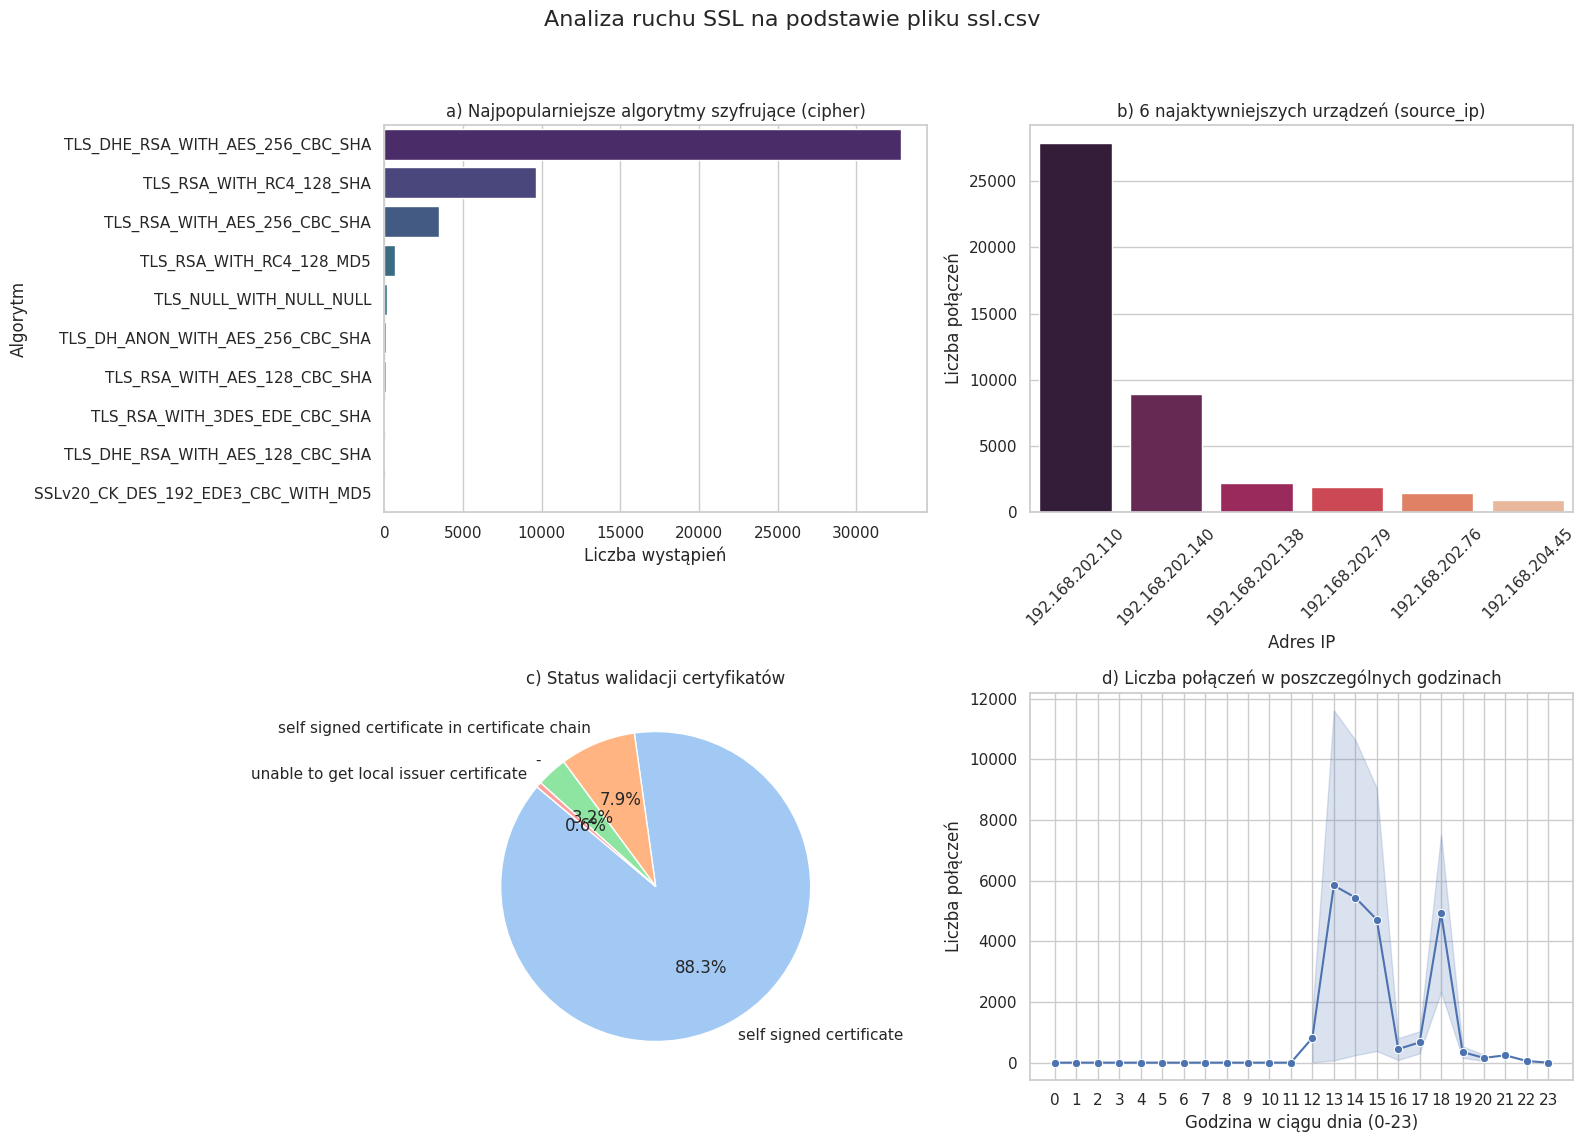

Najpopularniejszy szyfr to: TLS_DHE_RSA_WITH_AES_256_CBC_SHA (użyty 32846 razy)
Najczęstszy status certyfikatu to: self signed certificate


In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Wczytanie danych z automatycznym wykrywaniem separatora
df = pd.read_csv('ssl.csv', sep=None, engine='python')

# Ustawienie estetycznego stylu dla wykresów
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Analiza ruchu SSL na podstawie pliku ssl.csv', fontsize=16)

# a) Najpopularniejsze algorytmy szyfrujące
cipher_counts = df['cipher'].value_counts()
sns.barplot(
    y=cipher_counts.head(10).index,
    x=cipher_counts.head(10).values,
    ax=axes[0, 0],
    palette='viridis',
    hue=cipher_counts.head(10).index,
    legend=False
)
axes[0, 0].set_title('a) Najpopularniejsze algorytmy szyfrujące (cipher)')
axes[0, 0].set_xlabel('Liczba wystąpień')
axes[0, 0].set_ylabel('Algorytm')

# b) 6 najaktywniejszych urządzeń
top_6_ips = df['source_ip'].value_counts().head(6)
sns.barplot(
    x=top_6_ips.index,
    y=top_6_ips.values,
    ax=axes[0, 1],
    palette='rocket',
    hue=top_6_ips.index,
    legend=False
)
axes[0, 1].set_title('b) 6 najaktywniejszych urządzeń (source_ip)')
axes[0, 1].set_xlabel('Adres IP')
axes[0, 1].set_ylabel('Liczba połączeń')
axes[0, 1].tick_params(axis='x', rotation=45)

# c) Status walidacji certyfikatów (certificate_validation_status)
# Zamiana ewentualnych wartości NaN na znak '-'
df['certificate_validation_status'] = df['certificate_validation_status'].fillna('-')
cert_counts = df['certificate_validation_status'].value_counts()
axes[1, 0].pie(cert_counts.values, labels=cert_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette("pastel"))
axes[1, 0].set_title('c) Status walidacji certyfikatów')

# d) Liczba połączeń w poszczególnych godzinach
# Konwersja czasu Unix na standardowy format daty i czasu
df['datetime'] = pd.to_datetime(df['timestamp_unix'], unit='s')
hourly_counts = df.set_index('datetime')['connection_uid'].resample('h').size()
sns.lineplot(x=hourly_counts.index.hour, y=hourly_counts.values, ax=axes[1, 1], marker='o', color='b')
axes[1, 1].set_title('d) Liczba połączeń w poszczególnych godzinach')
axes[1, 1].set_xlabel('Godzina w ciągu dnia (0-23)')
axes[1, 1].set_ylabel('Liczba połączeń')
axes[1, 1].set_xticks(range(24))

# Dopasowanie układu i wyświetlenie wyników
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# Wypisanie najważniejszych statystyk do konsoli
print(f"Najpopularniejszy szyfr to: {cipher_counts.index[0]} (użyty {cipher_counts.values[0]} razy)")
print(f"Najczęstszy status certyfikatu to: {cert_counts.index[0]}")